# 01 Explore: first look at title.basics

- **Reads:** data/raw/title.basics.tsv.gz
- **Writes:** nothing
- **Run after:** nothing (needs the Sprint 1 downloads in data/raw/)

What I found: movies go back to 1892, and there are 760,303 movies in the file. TV episodes make up most of it, so every later notebook filters to movies first.

In [1]:
import csv
import pandas as pd

RAW = "../data/raw"
BASICS = f"{RAW}/title.basics.tsv.gz"

In [2]:
sample = pd.read_csv(
    BASICS,
    sep="\t",
    na_values="\\N",
    quoting=csv.QUOTE_NONE,
    nrows=1000,
)
sample.head(10)

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894.0,NaN,1.0,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892.0,NaN,5.0,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892.0,NaN,5.0,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892.0,NaN,12.0,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893.0,NaN,1.0,Short
5,tt0000006,short,Chinese Opium Den,Chinese Opium Den,0,1894.0,NaN,1.0,Short
6,tt0000007,short,Corbett and Courtney Before the Kinetograph,Corbett and Courtney Before the Kinetograph,0,1894.0,NaN,1.0,"Short,Sport"
7,tt0000008,short,Edison Kinetoscopic Record of a Sneeze,Edison Kinetoscopic Record of a Sneeze,0,1894.0,NaN,1.0,"Documentary,Short"
8,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance
9,tt0000010,short,Leaving the Factory,La sortie de l'usine Lumière à Lyon,0,1895.0,NaN,1.0,"Documentary,Short"


In [3]:
sample.info()
print("Sample memory (MB):", round(sample.memory_usage(deep=True).sum() / 1e6, 2))

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   tconst          1000 non-null   str    
 1   titleType       1000 non-null   str    
 2   primaryTitle    1000 non-null   str    
 3   originalTitle   1000 non-null   str    
 4   isAdult         1000 non-null   int64  
 5   startYear       999 non-null    float64
 6   endYear         0 non-null      float64
 7   runtimeMinutes  505 non-null    float64
 8   genres          984 non-null    str    
dtypes: float64(3), int64(1), str(5)
memory usage: 138.0 KB
Sample memory (MB): 0.14


In [4]:
%%time
cols = ["tconst", "titleType", "primaryTitle", "isAdult",
        "startYear", "runtimeMinutes", "genres"]

basics = pd.read_csv(
    BASICS,
    sep="\t",
    na_values="\\N",
    quoting=csv.QUOTE_NONE,
    usecols=cols,
    dtype={
        "tconst": "string[pyarrow]",
        "titleType": "category",
        "primaryTitle": "string[pyarrow]",
        "isAdult": "category",
        "startYear": "string[pyarrow]",
        "runtimeMinutes": "string[pyarrow]",
        "genres": "string[pyarrow]",
    },
)
print(basics.shape)

(12947333, 7)
CPU times: user 4.73 s, sys: 158 ms, total: 4.88 s
Wall time: 4.9 s


In [5]:
mb = basics.memory_usage(deep=True) / 1e6
print(mb.round(1))
print("Total MB:", round(mb.sum(), 1))

Index               0.0
tconst            227.4
titleType          12.9
primaryTitle      364.6
isAdult            12.9
startYear         151.0
runtimeMinutes    114.8
genres            246.2
dtype: float64
Total MB: 1129.9


In [6]:
basics["titleType"].value_counts()

titleType
tvEpisode       10022141
short            1168126
movie             760303
video             333242
tvSeries          307991
tvMovie           156961
tvMiniSeries       74124
tvSpecial          62345
videoGame          50991
tvShort            11108
tvPilot                1
Name: count, dtype: int64

In [7]:
basics[basics["titleType"] == "tvPilot"]

,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres
3821057,tt15258334,tvPilot,TV Pilot,0,1991,<NA>,<NA>


In [8]:
(basics.isna().mean() * 100).round(1).sort_values(ascending=False)

runtimeMinutes    62.2
startYear         11.5
genres             4.2
tconst             0.0
titleType          0.0
primaryTitle       0.0
isAdult            0.0
dtype: float64

In [9]:
movies = basics[basics["titleType"] == "movie"]
print(len(movies), "movies")
movies.sample(10, random_state=42)

760303 movies


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres
7724285,tt3231070,movie,Mama Sue's Garden,0,<NA>,65,"Documentary,Family"
8941833,tt3744574,movie,Ishimai,0,1922,<NA>,<NA>
10354953,tt45536590,movie,Manraj,0,<NA>,<NA>,<NA>
3664533,tt14966364,movie,"LOVE ME, STUPID",0,<NA>,110,"Comedy,Family"
10223648,tt4404906,movie,No One's: Niciji,0,2014,52,Documentary
3724580,tt1507994,movie,The Road to Gaza,0,2009,66,"Documentary,News"
433289,tt0451788,movie,Terrifying Girls' High School: Lynch Law Class...,0,1973,88,"Action,Crime,Horror"
122358,tt0125723,movie,Documenta X - Die Filme,0,1997,<NA>,Documentary
11486494,tt6710198,movie,Maina,0,2008,<NA>,Biography
10601638,tt49067095,movie,LADJI YORO: L'espoir mort pour l'espoir,0,<NA>,<NA>,Documentary


<Axes: title={'center': 'Movies by decade'}, xlabel='startYear'>

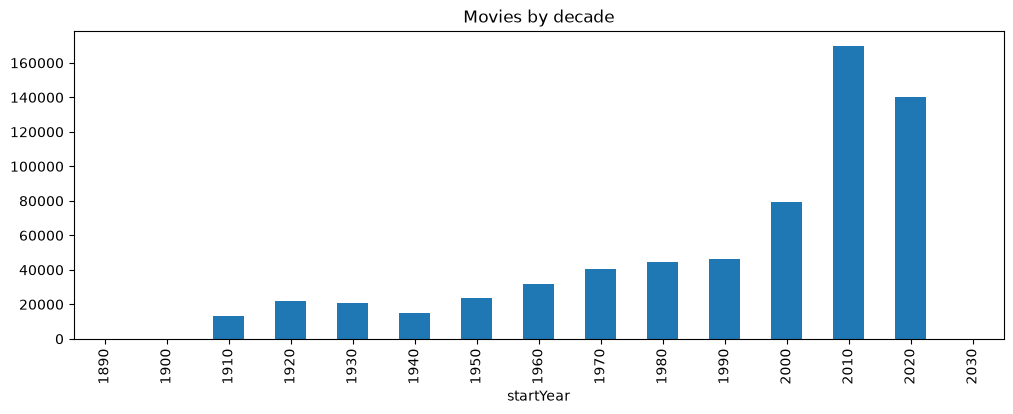

In [10]:
years = pd.to_numeric(movies["startYear"], errors="coerce")
decade = (years // 10) * 10
decade.value_counts().sort_index().plot(kind="bar", figsize=(12, 4), title="Movies by decade")

## First observations
- Movies date back to 1892
- Based on the data downloaded we have 760,303 movies so far. Somehow that number felt small to me; I thought it would be in the millions at least
- Curious to know why there was only one tvPilot title type: found out that it was just a blank TV pilot on IMDb - https://www.imdb.com/title/tt15258334/
- Double count from 2000 to 2010, interesting to see where it will end with 2020